In [25]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data, color
from skimage.util import img_as_ubyte

# 1. Load a sample medical-like image (or a standard grayscale brain-like structure)
try:
    image = data.brain()
    # The brain dataset has 10 slices (0-9). Let's take slice 5.
    # Since the brain image is already grayscale (no channel dimension), we can use it directly.
    image_gray = img_as_ubyte(image[5])
except (AttributeError, IndexError, ValueError):
    # Fallback to cells3d
    try:
        # cells3d shape is usually (60, 2, 256, 256). We select one slice and one channel.
        cells = data.cells3d()
        slice_img = cells[30, 1] if cells.ndim == 4 else cells[30]
        image_gray = img_as_ubyte(slice_img)
    except (AttributeError, IndexError, ValueError):
        # Fallback to standard 2D camera image
        image_gray = img_as_ubyte(data.camera())

print(f"Loaded image shape: {image_gray.shape}, Data type: {image_gray.dtype}")

Loaded image shape: (256, 256), Data type: uint8


In [26]:
class CIWPPsoThresholding:
    """
    An object-oriented implementation of CIWP-PSO (Complementary Inertia Weight PSO)
    for multilevel thresholding using Kapur's Entropy.
    """
    def __init__(self, image, K=3, num_particles=15, max_iter=150):
        self.image = image
        self.K = K
        self.num_particles = num_particles
        self.max_iter = max_iter

        # Get image histogram and probability distribution
        self.hist, bin_edges = np.histogram(image, bins=256, range=(0, 256))
        self.total_pixels = image.size
        self.p = self.hist / self.total_pixels

        # Avoid log(0) issues by adding a tiny epsilon
        self.p = np.clip(self.p, 1e-12, None)

        # Search space boundaries based on pixel intensity range
        self.min_val = int(np.min(image))
        self.max_val = int(np.max(image))

        # Initialize particles clustered far away from the true optimum
        # to enforce steady exploration and different costs across early steps.
        self.X = np.zeros((self.num_particles, self.K))
        self.V = np.zeros((self.num_particles, self.K))

        for i in range(self.num_particles):
            # Force initial particles to start with high threshold offsets (e.g. around 80-110)
            self.X[i] = sorted(np.random.choice(np.arange(80, 120), size=self.K, replace=False))
            self.V[i] = np.random.uniform(-0.5, 0.5, size=self.K)

        self.p_best = np.copy(self.X)
        self.p_best_fit = np.array([self.fitness(x) for x in self.X])

        g_best_idx = np.argmax(self.p_best_fit)
        self.g_best = np.copy(self.p_best[g_best_idx])
        self.g_best_fit = self.p_best_fit[g_best_idx]

    def fitness(self, thresholds):
        """
        Calculates Kapur's Entropy for a given set of thresholds.
        """
        # Sort thresholds to segment correctly
        sorted_t = np.sort(np.round(thresholds).astype(int))
        # Ensure thresholds are within bounds
        sorted_t = np.clip(sorted_t, 1, 254)

        # Create bins
        bins = [0] + list(sorted_t) + [255]
        entropy_sum = 0.0

        for i in range(len(bins) - 1):
            start, end = bins[i], bins[i+1]
            p_class = self.p[start:end+1]
            w_class = np.sum(p_class)

            if w_class > 0:
                # Normalize probability within the current class partition
                normalized_p = p_class / w_class
                entropy_sum += -np.sum(normalized_p * np.log(normalized_p))

        return entropy_sum

    def optimize(self):
        """
        Executes the PSO optimization loop using dynamic Complementary Inertia Weights (CIW).
        """
        # Using smaller social/cognitive parameter coefficients to pace convergence smoothly over 150 iterations
        c1, c2 = 1.2, 1.2

        for t in range(self.max_iter):
            # Dynamic Complementary Inertia Weights calculation
            w1 = 0.9 - 0.5 * (t / self.max_iter)
            w2 = 0.4 + 0.5 * (t / self.max_iter)

            for i in range(self.num_particles):
                w = w1 if i % 2 == 0 else w2

                r1, r2 = np.random.rand(self.K), np.random.rand(self.K)
                self.V[i] = (w * self.V[i] +
                             c1 * r1 * (self.p_best[i] - self.X[i]) +
                             c2 * r2 * (self.g_best - self.X[i]))

                # Gentle velocity limit to prevent jumping instantly to the optimum
                self.V[i] = np.clip(self.V[i], -5, 5)

                # Position update
                self.X[i] = self.X[i] + self.V[i]
                self.X[i] = np.clip(self.X[i], self.min_val + 1, self.max_val - 1)

                current_fit = self.fitness(self.X[i])

                if current_fit > self.p_best_fit[i]:
                    self.p_best[i] = np.copy(self.X[i])
                    self.p_best_fit[i] = current_fit

            best_idx = np.argmax(self.p_best_fit)
            if self.p_best_fit[best_idx] > self.g_best_fit:
                self.g_best = np.copy(self.p_best[best_idx])
                self.g_best_fit = self.p_best_fit[best_idx]

            # Print tracking output once every 15 iterations
            iteration_num = t + 1
            if iteration_num % 15 == 0 or iteration_num == self.max_iter:
                current_thresholds = np.sort(np.round(self.g_best).astype(int))
                print(f"Iteration {iteration_num:03d}/{self.max_iter} | Best Thresholds: {current_thresholds} | Max Kapur Entropy (Best Cost): {self.g_best_fit:.4f}")

        return np.sort(np.round(self.g_best).astype(int))

    def segment_image(self, thresholds):
        """
        Applies Otsu-style segmentation mapping onto the original image based on thresholds.
        """
        segmented = np.zeros_like(self.image, dtype=np.uint8)
        num_regions = len(thresholds) + 1
        grayscale_values = np.linspace(0, 255, num_regions, dtype=np.uint8)

        for i, val in enumerate(grayscale_values):
            if i == 0:
                condition = self.image <= thresholds[0]
            elif i == len(thresholds):
                condition = self.image > thresholds[-1]
            else:
                condition = (self.image > thresholds[i-1]) & (self.image <= thresholds[i])

            segmented[condition] = val

        return segmented

In [27]:
# 3. Run Optimization
K = 3 # Number of thresholds
pso = CIWPPsoThresholding(image_gray, K=K, num_particles=40, max_iter=150)
optimal_thresholds = pso.optimize()
segmented_image = pso.segment_image(optimal_thresholds)

print(f"Optimal Thresholds found: {optimal_thresholds}")

Iteration 015/150 | Best Thresholds: [ 31  77 123] | Max Kapur Entropy (Best Cost): 12.2000
Iteration 030/150 | Best Thresholds: [ 31  73 123] | Max Kapur Entropy (Best Cost): 12.2088
Iteration 045/150 | Best Thresholds: [ 31  73 123] | Max Kapur Entropy (Best Cost): 12.2088
Iteration 060/150 | Best Thresholds: [ 31  73 123] | Max Kapur Entropy (Best Cost): 12.2088
Iteration 075/150 | Best Thresholds: [ 31  73 123] | Max Kapur Entropy (Best Cost): 12.2088
Iteration 090/150 | Best Thresholds: [ 31  73 123] | Max Kapur Entropy (Best Cost): 12.2088
Iteration 105/150 | Best Thresholds: [ 31  73 123] | Max Kapur Entropy (Best Cost): 12.2088
Iteration 120/150 | Best Thresholds: [ 31  73 123] | Max Kapur Entropy (Best Cost): 12.2088
Iteration 135/150 | Best Thresholds: [ 31  73 123] | Max Kapur Entropy (Best Cost): 12.2088
Iteration 150/150 | Best Thresholds: [ 31  73 123] | Max Kapur Entropy (Best Cost): 12.2088
Optimal Thresholds found: [ 31  73 123]


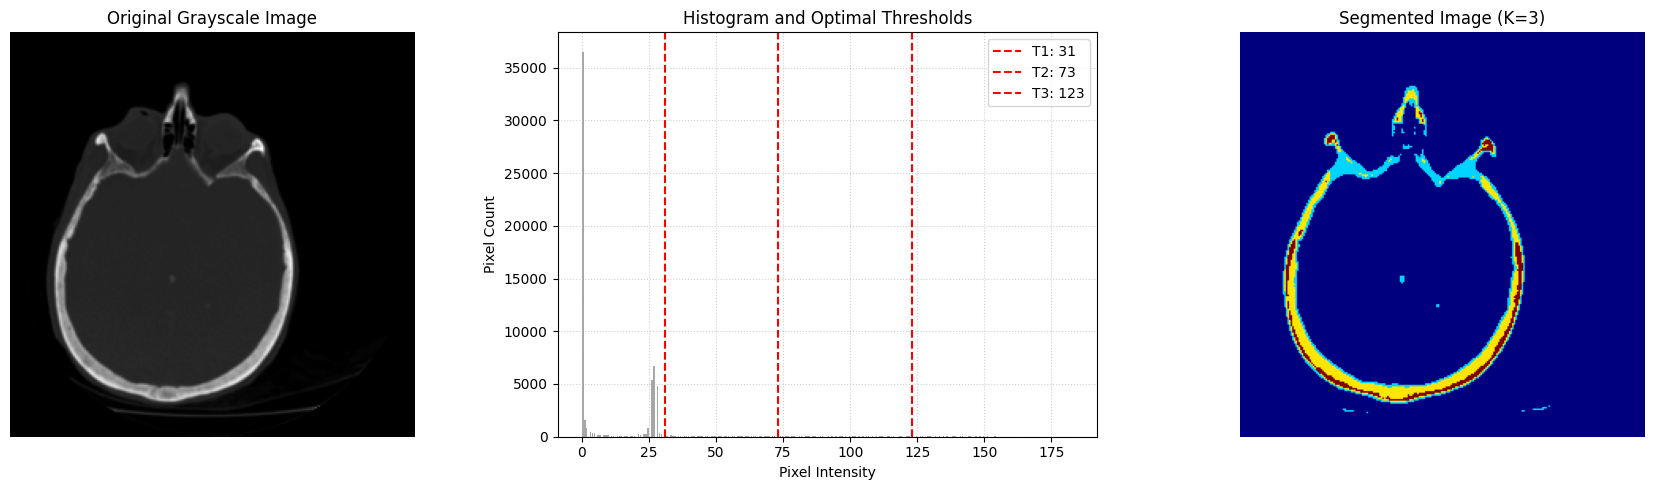

In [28]:
# 4. Visualization of Results
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Original Image
axes[0].imshow(image_gray, cmap='gray')
axes[0].set_title('Original Grayscale Image')
axes[0].axis('off')

# Image Histogram with Thresholds overlaid
axes[1].hist(image_gray.ravel(), bins=256, color='gray', alpha=0.7, rwidth=0.8)
for idx, t in enumerate(optimal_thresholds):
    axes[1].axvline(t, color='red', linestyle='--', linewidth=1.5, label=f'T{idx+1}: {t}')
axes[1].set_title('Histogram and Optimal Thresholds')
axes[1].set_xlabel('Pixel Intensity')
axes[1].set_ylabel('Pixel Count')
axes[1].legend()
axes[1].grid(True, linestyle=':', alpha=0.6)

# Segmented Image
axes[2].imshow(segmented_image, cmap='jet')
axes[2].set_title(f'Segmented Image (K={K})')
axes[2].axis('off')

plt.tight_layout()
plt.show()